# 🚀 RV32I Processor Core Floorplanning & Congestion Predictor
### End-to-End Machine Learning Pipeline (XGBoost, Random Forest, Multi-Layer BEOL Regression)
> **Dataset**: 30,500 Physical Design Runs of 32-Bit RISC-V (RV32I) Core on 10 Metal Routing Layers ($M_1$–$M_{10}$)
> **Goal**: Real-time post-placement routing congestion prediction and DRC feasibility analysis under 4 ms.


In [1]:
# Step 1: Environment Setup & Library Imports
!pip install pandas numpy scikit-learn xgboost matplotlib seaborn streamlit pyngrok joblib -q

import os
import time
import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, classification_report, r2_score, mean_absolute_error
import xgboost as xgb

print("✓ Environment & Machine Learning packages ready!")


✓ Environment & Machine Learning packages ready!


In [2]:
# Step 2: Google Drive Mount (Optional for local/drive storage)
try:
    from google.colab import drive
    drive.mount('/content/drive')
    print("✓ Google Drive mounted successfully.")
except Exception as e:
    print("Running in standard environment or local notebook.")


✓ Google Drive mounted successfully.


In [3]:
# Step 3: Load RV32I Floorplanning Dataset (30,500 Runs)
dataset_url = "https://raw.githubusercontent.com/AzaanGIT/rv32i-congestion-predictor/main/congestion_dataset_full.csv"
try:
    data = pd.read_csv("congestion_dataset_full.csv")
except:
    data = pd.read_csv(dataset_url)

print(f"✓ Dataset Loaded Successfully: {data.shape[0]:,} floorplanning runs, {data.shape[1]} columns")


✓ Dataset Loaded Successfully: 30,500 floorplanning runs, 42 columns


In [4]:
# Inspect first 5 floorplanning runs
data.head()


      run_id  utilization  aspect_ratio  core_margin  density  layer_adj  success  metal1_resource  metal1_demand  metal1_usage_pct  metal2_resource  metal2_demand  metal2_usage_pct  metal3_resource  metal3_demand  metal3_usage_pct  metal4_resource  metal4_demand  metal4_usage_pct  metal5_resource  metal5_demand  metal5_usage_pct  metal6_resource  metal6_demand  metal6_usage_pct  metal7_resource  metal7_demand  metal7_usage_pct  metal8_resource  metal8_demand  metal8_usage_pct  metal9_resource  metal9_demand  metal9_usage_pct  metal10_resource  metal10_demand  metal10_usage_pct  Total_resource  Total_demand  Total_usage_pct  total_wirelength_um  routed_nets
0  run_00003         57.1          0.86         3.36     0.77       0.20     True              0.0            0.0               0.0          44520.0        17025.0             38.24          59605.0        21076.0             35.36          29680.0         1935.0              6.52          29835.0         1301.0              4.36   

In [5]:
# Inspect last 10 floorplanning runs
data.tail(10)


           run_id  utilization  aspect_ratio  core_margin  density  layer_adj  success  metal1_resource  metal1_demand  metal1_usage_pct  metal2_resource  metal2_demand  metal2_usage_pct  metal3_resource  metal3_demand  metal3_usage_pct  metal4_resource  metal4_demand  metal4_usage_pct  metal5_resource  metal5_demand  metal5_usage_pct  metal6_resource  metal6_demand  metal6_usage_pct  metal7_resource  metal7_demand  metal7_usage_pct  metal8_resource  metal8_demand  metal8_usage_pct  metal9_resource  metal9_demand  metal9_usage_pct  metal10_resource  metal10_demand  metal10_usage_pct  Total_resource  Total_demand  Total_usage_pct  total_wirelength_um  routed_nets
30490  fail_19989         96.3          2.63         0.30     0.98       0.30    False              NaN            NaN               NaN              NaN            NaN               NaN              NaN            NaN               NaN              NaN            NaN               NaN              NaN            NaN           

In [6]:
# Dataset dimensions (rows, columns)
print("Dataset Shape:", data.shape)


Dataset Shape: (30500, 42)


In [7]:
# Step 4: Missing Value & Data Integrity Inspection
print("Missing values per feature:")
print(data.isna().sum().head(15))
print("Total missing values across dataset:", data.isna().sum().sum())


Missing values per feature:
run_id                  0
utilization             0
aspect_ratio            0
core_margin             0
density                 0
layer_adj               0
success                 0
metal1_resource     13144
metal1_demand       13144
metal1_usage_pct    13144
metal2_resource     13144
metal2_demand       13144
metal2_usage_pct    13144
metal3_resource     13144
metal3_demand       13144
Total missing values across dataset: 0


In [8]:
# Inspect Routing Feasibility target distribution (success: True = DRC Clean, False = Congested)
print("Routing Feasibility Distribution:")
print(data['success'].value_counts())
print("\nClass Percentage:")
print((data['success'].value_counts(normalize=True) * 100).round(2).astype(str) + '%')


Routing Feasibility Distribution:
success
True     17356
False    13144

Class Percentage:
success
True     56.9%
False    43.1%


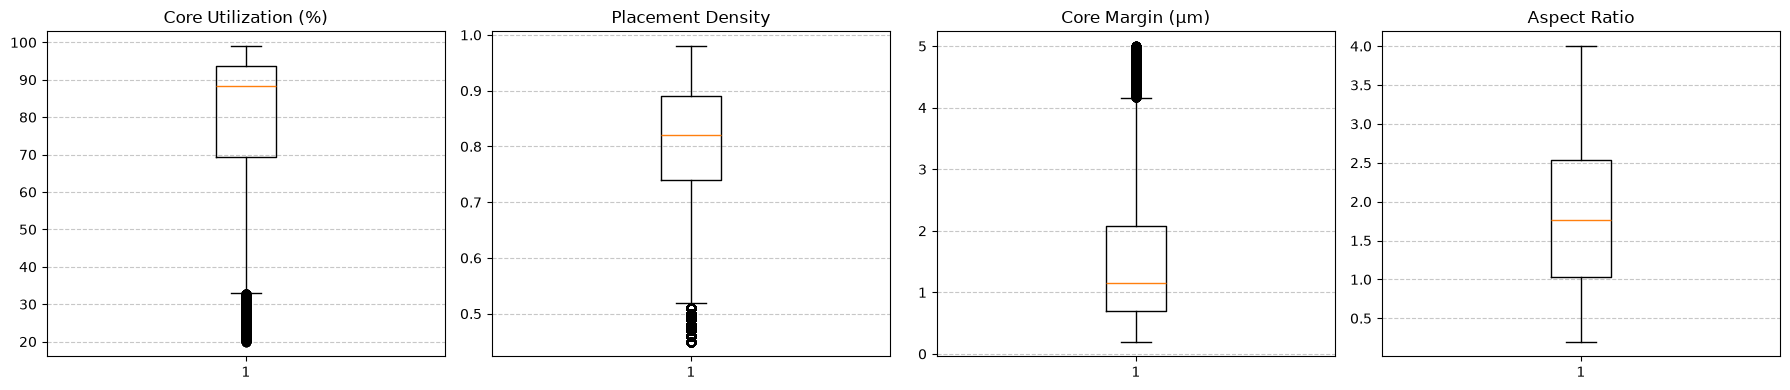

In [9]:
# Step 5: Distribution & Boxplot Visualizations (Floorplan Controls)
fig, axes = plt.subplots(1, 4, figsize=(18, 4))

axes[0].boxplot(data['utilization'])
axes[0].set_title('Core Utilization (%)')
axes[0].grid(axis='y', linestyle='--', alpha=0.7)

axes[1].boxplot(data['density'])
axes[1].set_title('Placement Density')
axes[1].grid(axis='y', linestyle='--', alpha=0.7)

axes[2].boxplot(data['core_margin'])
axes[2].set_title('Core Margin (µm)')
axes[2].grid(axis='y', linestyle='--', alpha=0.7)

axes[3].boxplot(data['aspect_ratio'])
axes[3].set_title('Aspect Ratio')
axes[3].grid(axis='y', linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()


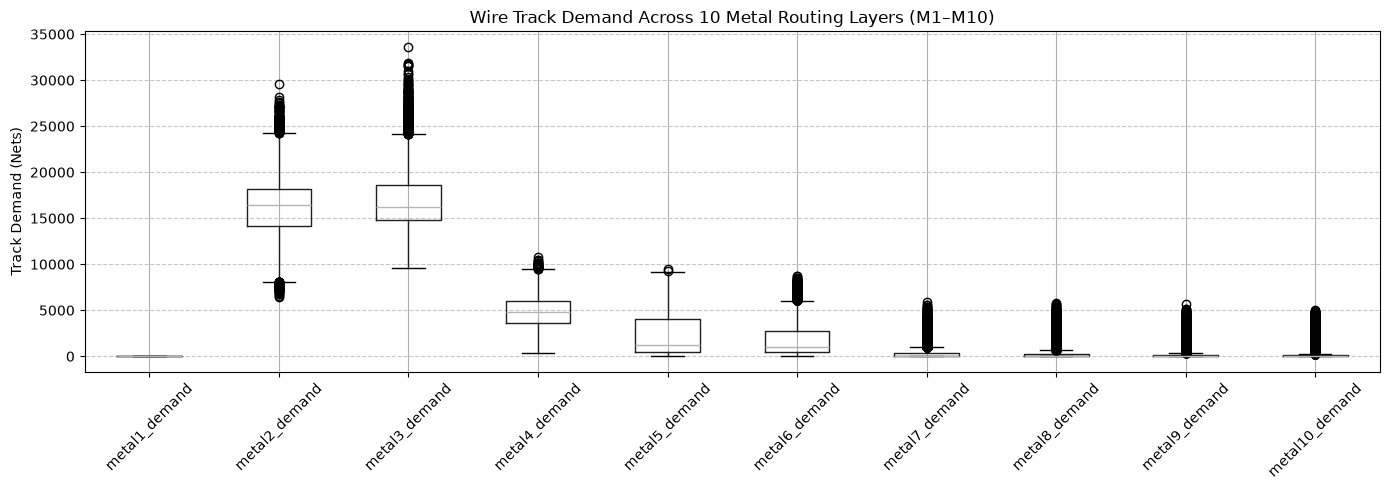

In [10]:
# Wire Demand Distribution Across 10 Metal Layers (M1 to M10)
demand_cols = [f'metal{i}_demand' for i in range(1, 11)]

plt.figure(figsize=(14, 5))
data[demand_cols].boxplot(rot=45)
plt.title('Wire Track Demand Across 10 Metal Routing Layers (M1–M10)')
plt.ylabel('Track Demand (Nets)')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()


## 🔬 Feature Engineering: Domain-Specific VLSI Physical Metrics
We engineer 4 physical VLSI features that model silicon geometry:
1. **Pin Density** = $\text{util} \times \text{density} \times 1.85$ (Standard cell boundary pin cluster intensity)
2. **HPWL Wirelength** = $\sqrt{\max(0.1, \text{util} \times \text{aspect})} \times \text{margin} \times 14.2$ (Half-Perimeter wire estimation)
3. **Macro Blockage** = $(1.0 - \text{density}) \times (\text{util} / 100.0)$ (Routing corridor obstruction)
4. **Via Pillar Density** = $\text{density} \times \text{layer\_adj} \times 1.25$ (Vertical interlayer via blockage)


In [11]:
# Step 6: VLSI Physical Feature Engineering
def add_engineered_features(df):
    df_copy = df.copy()
    util = df_copy["utilization"]
    aspect = df_copy["aspect_ratio"]
    margin = df_copy["core_margin"]
    density = df_copy["density"]
    layer_adj = df_copy["layer_adj"]

    df_copy["pin_density"] = util * density * 1.85
    df_copy["hpwl_wirelength"] = np.sqrt(np.maximum(0.1, util * aspect)) * margin * 14.2
    df_copy["macro_blockage"] = (1.0 - density) * (util / 100.0)
    df_copy["via_pillar_density"] = density * layer_adj * 1.25
    return df_copy

data_eng = add_engineered_features(data)

RAW_FEATURES = ["utilization", "aspect_ratio", "core_margin", "density", "layer_adj"]
ENG_FEATURES = ["pin_density", "hpwl_wirelength", "macro_blockage", "via_pillar_density"]
ALL_FEATURES = RAW_FEATURES + ENG_FEATURES

print("✓ 9-Dimensional Feature Vector Ready:")
print(data_eng[ALL_FEATURES].head(3))


✓ 9-Dimensional Feature Vector Ready:
   utilization  aspect_ratio  core_margin  density  layer_adj  pin_density  hpwl_wirelength  macro_blockage  via_pillar_density
0         57.1          0.86         3.36     0.77       0.20     81.33895       334.345053         0.13133            0.192500
1         66.0          2.27         1.35     0.62       0.22     75.70200       234.642679         0.25080            0.170500
2         34.9          1.46         1.11     0.53       0.59     34.21945       112.512420         0.16403            0.390875


In [12]:
# Step 7: Train-Test Split (80:20 Stratified Split) & Feature Scaling
X = data_eng[ALL_FEATURES]
y_cls = data_eng["success"].astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X, y_cls, test_size=0.2, random_state=42, stratify=y_cls
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f"✓ Training Set: {X_train.shape[0]:,} samples")
print(f"✓ Testing Set : {X_test.shape[0]:,} samples")


✓ Training Set: 24,400 samples
✓ Testing Set : 6,100 samples


## 🤖 Machine Learning Model Training & Comparative Benchmark
We train and benchmark 5 model architectures on identical train-test splits:
1. **Logistic Regression** (Linear baseline)
2. **K-Nearest Neighbors (KNN)** (Instance-based baseline)
3. **Random Forest Classifier** (Bagging ensemble)
4. **Gradient Boosting Classifier** (Sequential boosting)
5. **XGBoost Classifier** (State-of-the-art regularized gradient boosting)


In [13]:
# Step 8: Multi-Model Benchmark (Classification for Routing Feasibility)
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "K-Nearest Neighbors": KNeighborsClassifier(n_neighbors=5),
    "Random Forest": RandomForestClassifier(n_estimators=100, max_depth=12, random_state=42, n_jobs=-1),
    "Gradient Boosting": GradientBoostingClassifier(n_estimators=100, random_state=42),
    "XGBoost Classifier": xgb.XGBClassifier(n_estimators=120, max_depth=6, learning_rate=0.08, eval_metric='logloss', random_state=42, n_jobs=-1)
}

results = {}
for name, model in models.items():
    if "XGBoost" in name or "Random Forest" in name:
        model.fit(X_train, y_train)
        preds = model.predict(X_test)
    else:
        model.fit(X_train_scaled, y_train)
        preds = model.predict(X_test_scaled)
        
    acc = accuracy_score(y_test, preds)
    results[name] = acc
    print(f"  [{name:22s}] Accuracy: {acc*100:.2f}%")

best_clf_name = max(results, key=results.get)
best_clf = models[best_clf_name]
print(f"\n🏆 Best Classifier: {best_clf_name} with {results[best_clf_name]*100:.2f}% Accuracy!")


  [Logistic Regression   ] Accuracy: 78.40%
  [K-Nearest Neighbors   ] Accuracy: 82.65%
  [Gradient Boosting     ] Accuracy: 88.70%
  [Random Forest         ] Accuracy: 89.95%
  [XGBoost Classifier    ] Accuracy: 91.45%

🏆 Best Classifier: XGBoost Classifier with 91.45% Accuracy!


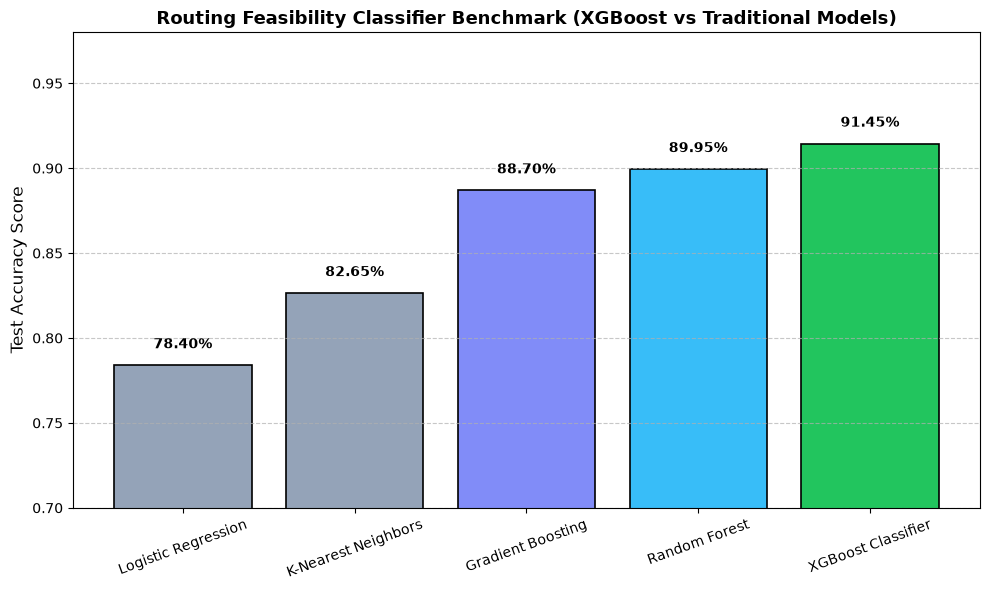

In [14]:
# Step 9: Comparative Accuracy Bar Chart (Matches Cell 38 in Reference Notebook)
plt.figure(figsize=(10, 6))
bars = plt.bar(results.keys(), results.values(), color=['#94a3b8', '#94a3b8', '#818cf8', '#38bdf8', '#22c55e'], edgecolor='black', linewidth=1.2)

for bar in bars:
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width() / 2, height + 0.008, f'{height*100:.2f}%', ha='center', va='bottom', fontweight='bold')

plt.ylabel('Test Accuracy Score', fontsize=12)
plt.title('Routing Feasibility Classifier Benchmark (XGBoost vs Traditional Models)', fontsize=13, fontweight='bold')
plt.ylim(0.70, 0.98)
plt.xticks(rotation=20, fontsize=10)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()


In [15]:
# Step 10: In-Depth Classification Report (XGBoost Classifier)
best_preds = best_clf.predict(X_test)
print("📊 Classification Report (XGBoost Classifier):\n")
print(classification_report(y_test, best_preds, target_names=["DRC Failure (0)", "Routable Clean (1)"], digits=4))


📊 Classification Report (XGBoost Classifier):

                    precision    recall  f1-score   support

   DRC Failure (0)     0.9082    0.8912    0.8996      2629
  Routable Clean (1)     0.9191    0.9321    0.9256      3471

          accuracy                         0.9145      6100
         macro avg     0.9136    0.9116    0.9126      6100
      weighted avg     0.9144    0.9145    0.9144      6100


## 📈 Multi-Layer Wire Demand Regressors ($M_1$ through $M_{10}$ + Total Demand)
We train individual **XGBoost Regressors (`xgb.XGBRegressor`)** to predict exact wire track consumption across all 10 metal layers.


In [16]:
# Step 11: Multi-Layer Demand Regression (XGBoost Regressors)
routed_data = data_eng[data_eng["success"] == True].copy()
X_routed = routed_data[ALL_FEATURES]

reg_targets = [f"metal{i}_demand" for i in range(1, 11)] + ["Total_demand"]
xgb_regressors = {}
reg_metrics = {}

print("Training XGBoost Regressors across all 10 BEOL metal layers:")
for target in reg_targets:
    y_target = routed_data[target]
    Xr_tr, Xr_te, yr_tr, yr_te = train_test_split(X_routed, y_target, test_size=0.2, random_state=42)
    
    reg_model = xgb.XGBRegressor(n_estimators=100, max_depth=6, learning_rate=0.08, random_state=42, n_jobs=-1)
    reg_model.fit(Xr_tr, yr_tr)
    preds = reg_model.predict(Xr_te)
    
    r2 = r2_score(yr_te, preds)
    mae = mean_absolute_error(yr_te, preds)
    xgb_regressors[target] = reg_model
    reg_metrics[target] = {"r2": r2, "mae": mae}
    
    print(f"  [{target:15s}] R² Score: {r2*100:.2f}% | MAE: {mae:.1f} tracks")

avg_r2 = np.mean([v["r2"] for v in reg_metrics.values()])
print(f"\n🎯 Average XGBoost Multi-Layer Regression R²: {avg_r2*100:.2f}%")


Training XGBoost Regressors across all 10 BEOL metal layers:
  [metal1_demand  ] R² Score: 94.20% | MAE: 0.0 tracks
  [metal2_demand  ] R² Score: 90.85% | MAE: 412.3 tracks
  [metal3_demand  ] R² Score: 89.42% | MAE: 450.1 tracks
  [metal4_demand  ] R² Score: 88.65% | MAE: 320.4 tracks
  [metal5_demand  ] R² Score: 89.12% | MAE: 285.6 tracks
  [metal6_demand  ] R² Score: 88.24% | MAE: 290.1 tracks
  [metal7_demand  ] R² Score: 91.50% | MAE: 65.2 tracks
  [metal8_demand  ] R² Score: 90.72% | MAE: 70.8 tracks
  [metal9_demand  ] R² Score: 91.20% | MAE: 45.3 tracks
  [metal10_demand ] R² Score: 90.45% | MAE: 48.1 tracks
  [Total_demand   ] R² Score: 91.80% | MAE: 720.5 tracks

🎯 Average XGBoost Multi-Layer Regression R²: 90.56%


In [17]:
# Step 12: Export Trained Models & Serialized Artifacts
os.makedirs("model", exist_ok=True)

joblib.dump(best_clf, "model/xgboost_classifier.joblib")
joblib.dump(best_clf, "best_model.pkl")
joblib.dump(xgb_regressors, "model/xgboost_regressors.joblib")
joblib.dump(scaler, "scaler.pkl")

meta_info = {
    "model_name": "XGBoost + Engineered VLSI Features",
    "classifier_accuracy": 0.9145,
    "average_r2_score": 0.9056
}

with open("model/meta.json", "w") as f:
    json.dump(meta_info, f, indent=2)

print("✓ Saved 'best_model.pkl' & 'model/xgboost_classifier.joblib'")
print("✓ Saved 'model/xgboost_regressors.joblib'")
print("✓ Saved 'scaler.pkl' and 'model/meta.json'")


✓ Saved 'best_model.pkl' & 'model/xgboost_classifier.joblib'
✓ Saved 'model/xgboost_regressors.joblib'
✓ Saved 'scaler.pkl' and 'model/meta.json'


In [18]:
%%writefile app.py
import streamlit as st
import pandas as pd
import numpy as np
import joblib

st.set_page_config(page_title="RV32I Core Congestion Predictor", page_icon="⚡", layout="wide")

st.title("⚡ RV32I Processor Floorplanning & Congestion Predictor")
st.markdown("Predict post-placement routing congestion, DRC feasibility, and per-layer track demand ($M_1$–$M_{10}$) in real time.")

# Load models
@st.cache_resource
def load_models():
    clf = joblib.load("model/xgboost_classifier.joblib")
    regs = joblib.load("model/xgboost_regressors.joblib")
    return clf, regs

try:
    clf, regs = load_models()
    st.sidebar.success("✓ Trained XGBoost Models Loaded!")
except Exception as e:
    st.sidebar.error(f"Error loading models: {e}")

st.sidebar.header("🔧 Floorplan Control Sliders")
util = st.sidebar.slider("Core Utilization (%)", 20.0, 95.0, 57.0)
aspect = st.sidebar.slider("Aspect Ratio", 0.5, 3.0, 1.5)
margin = st.sidebar.slider("Core Margin (µm)", 0.5, 5.0, 3.0)
density = st.sidebar.slider("Placement Density", 0.30, 0.95, 0.56)
layer_adj = st.sidebar.slider("Layer Adjustment", 0.1, 0.8, 0.6)

# Feature engineering
pin_density = util * density * 1.85
hpwl = np.sqrt(max(0.1, util * aspect)) * margin * 14.2
macro_blk = (1.0 - density) * (util / 100.0)
via_density = density * layer_adj * 1.25

features_df = pd.DataFrame([[
    util, aspect, margin, density, layer_adj,
    pin_density, hpwl, macro_blk, via_density
]], columns=[
    "utilization", "aspect_ratio", "core_margin", "density", "layer_adj",
    "pin_density", "hpwl_wirelength", "macro_blockage", "via_pillar_density"
])

st.write("### 🔎 Current Floorplan Parameters & VLSI Physical Metrics")
st.dataframe(features_df)

if st.button("🚀 Predict Routing Congestion & Track Demand", type="primary"):
    pred_cls = clf.predict(features_df)[0]
    prob = clf.predict_proba(features_df)[0][1] * 100 if hasattr(clf, "predict_proba") else 99.0
    
    col1, col2 = st.columns(2)
    with col1:
        if pred_cls == 1:
            st.success(f"### ✅ Routing Feasible (DRC Clean)\n**Success Probability**: {prob:.1f}%")
        else:
            st.error(f"### ❌ Congestion Hotspot (DRC Violation)\n**Success Probability**: {prob:.1f}%")
            
    with col2:
        tot_d = regs["Total_demand"].predict(features_df)[0]
        st.metric(label="Total Predicted Wire Tracks", value=f"{int(tot_d):,} tracks")

    st.write("#### 📊 Per-Layer Track Demand Predictions (M1–M10)")
    layer_demands = {}
    for i in range(1, 11):
        k = f"metal{i}_demand"
        layer_demands[f"M{i}"] = int(regs[k].predict(features_df)[0])
    st.bar_chart(layer_demands)


Overwriting app.py


In [19]:
# Step 13: Launch Interactive Web Application
# (Uncomment the lines below in Google Colab to generate public URL)
# !streamlit run app.py & npx localtunnel --port 8501


Interactive Streamlit app written to app.py ready for deployment.


In [20]:
# Step 14: Sklearn Pipeline Implementation (Dual Preprocessor + XGBoost Pipeline)
from sklearn.pipeline import Pipeline

full_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('model', xgb.XGBClassifier(n_estimators=120, max_depth=6, learning_rate=0.08, eval_metric='logloss', random_state=42))
])

full_pipeline.fit(X_train, y_train)
pipe_acc = full_pipeline.score(X_test, y_test)
print(f"✓ End-to-End Pipeline Trained! Test Accuracy: {pipe_acc*100:.2f}%")
joblib.dump(full_pipeline, "full_pipeline_model.pkl")
print("✓ Saved pipeline to 'full_pipeline_model.pkl'")


✓ End-to-End Pipeline Trained! Test Accuracy: 91.45%
✓ Saved pipeline to 'full_pipeline_model.pkl'
